# Exploratory data analysis (EDA)

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from zurich_uhi_lur import plot_utils

figwidth, figheight = plt.rcParams["figure.figsize"]
plot_utils.set_style()

In [2]:
# spatial extent
# agglom_extent_filepath = "../data/raw/zurich-extent.gpkg"
agglom_extent_filepath = "../data/processed/zurich-lcs-extent.gpkg"
stations_gdf_filepath = "../data/processed/stations.gpkg"
ts_df_filepath = "../data/processed/ts-df.csv"

t_label = r"$T$ [$^{\circ}$C]"
t_mean_label = r"$T_{\mathrm{mean}}$ [$^{\circ}$C]"
t_minus_mean_label = r"$T - T_{\mathrm{mean}}$ [$^{\circ}$C]"
t_std_label = r"$T_{\mathrm{std}}$ [$^{\circ}$C]"

dst_t_mean_maps_filepath = "../reports/figures/station-t-mean-maps.png"

# for plots
# the station maps span the widened text block of the article, drawn at their printed
# size (the width is per panel)
compare_maps_kwargs = dict(
    figwidth=plot_utils.WIDE_TEXT_WIDTH / 2,
    figheight=3.0,
    facecolor=(0.87, 0.56, 0.02, 0.2),
    edgecolor="gray",
)
savefig_map_kwargs = dict(dpi=300)

In [3]:
# Parameters
agglom_extent_filepath = "data/processed/zurich-lcs-extent.gpkg"
stations_gdf_filepath = "data/processed/stations.gpkg"
ts_df_filepath = "data/processed/ts-df.csv"
dst_t_mean_maps_filepath = "reports/figures/station-t-mean-maps.png"


In [4]:
region = gpd.read_file(agglom_extent_filepath)["geometry"].iloc[:1]

In [5]:
stations_gdf = gpd.read_file(stations_gdf_filepath)
# get the station id column label
station_id_col = stations_gdf.columns.difference(["geometry", "source"])[0]
# set the station id as index
stations_gdf = stations_gdf.set_index(station_id_col)
# show the data frame
stations_gdf

,source,geometry
station_id,,
REH,AWS,POINT (2681433 1253548)
SMA,AWS,POINT (2685223 1248410)
Zürich-Kaserne,AWS,POINT (2682450 1247990)
Dübendorf-Empa,AWS,POINT (2688300 1251105)
A10,LCS,POINT (2678150 1248450)
...,...,...
2807-1,LCS,POINT (2681745 1245038)
2810,LCS,POINT (2680785 1247588)
530,LCS,POINT (2679316 1250429)


In [6]:
ts_df = pd.read_csv(
    ts_df_filepath, index_col=["heatwave", "time"], parse_dates=["time"]
)
ts_df_dict = {
    source: ts_df[source_ser.index]
    for source, source_ser in stations_gdf.groupby("source", sort=False)
}

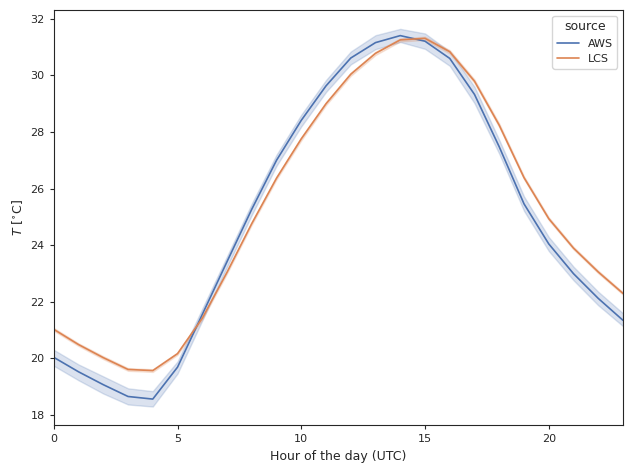

In [7]:
# diurnal cycle of the hot-day temperatures per source
plot_ts_df = pd.concat(
    [
        source_ts_df.reset_index()
        .melt(id_vars=["heatwave", "time"], var_name="station_id", value_name="T")
        .assign(source=source)
        for _, (source, source_ts_df) in enumerate(ts_df_dict.items())
    ],
    ignore_index=True,
)
plot_ts_df["hour"] = plot_ts_df["time"].dt.hour
ax = sns.lineplot(data=plot_ts_df, x="hour", y="T", hue="source")
ax.set(xlim=[0, 23], xlabel="Hour of the day (UTC)", ylabel=t_label)
ax.figure.tight_layout()

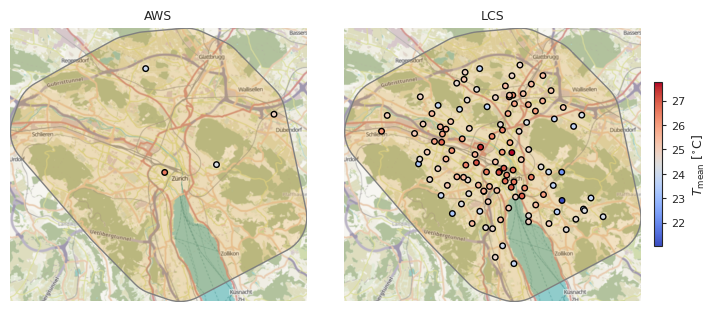

In [8]:
fig = plot_utils.compare_maps(
    stations_gdf,
    pd.concat(
        [source_ts_df.mean() for _, source_ts_df in ts_df_dict.items()],
        axis="rows",
    ),
    var_label=t_mean_label,
    region_gdf=region,
    **compare_maps_kwargs,
)
fig.savefig(dst_t_mean_maps_filepath, **savefig_map_kwargs)

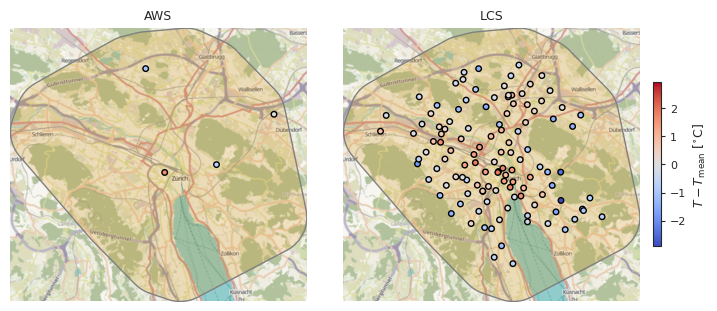

In [9]:
t_minus_mean_ser = pd.concat(
    [
        source_ts_df.apply(lambda row: row - row.mean(), axis="columns").mean()
        for _, source_ts_df in ts_df_dict.items()
    ],
    axis="rows",
)
max_abs = t_minus_mean_ser.abs().max()
fig = plot_utils.compare_maps(
    stations_gdf,
    t_minus_mean_ser,
    var_label=t_minus_mean_label,
    region_gdf=region,
    vmin=-max_abs,
    vmax=max_abs,
    **compare_maps_kwargs,
)

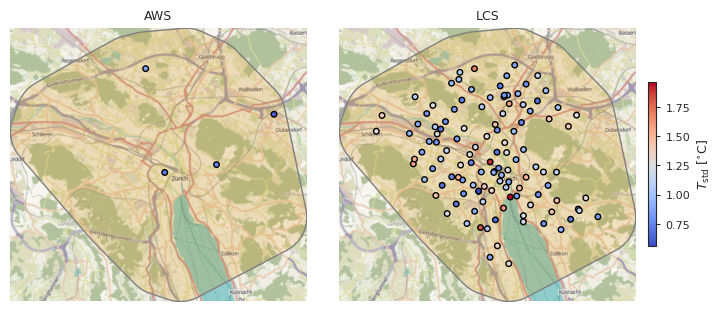

In [10]:
fig = plot_utils.compare_maps(
    stations_gdf,
    pd.concat(
        [
            source_ts_df.apply(lambda row: row - row.mean(), axis="columns").std()
            for _, source_ts_df in ts_df_dict.items()
        ],
        axis="rows",
    ),
    var_label=t_std_label,
    region_gdf=region,
    **compare_maps_kwargs,
)